## Import dependencies and load data

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

In [24]:
df = pd.read_csv("https://simplonline-v3-prod.s3.eu-west-3.amazonaws.com/media/file/csv/student-mental-health-6af1a2527d06c522087238.csv")

## Basic overview

In [25]:
df.info()
df.head()
df.columns
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   object 
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   object 
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   object 
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 19

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


## Missing values and outliers

In [26]:
# missing values in each column
df.isna().sum()
# percentage of missing values in each column
df.isna().sum() / len(df) * 100
df.duplicated().sum()

np.int64(0)

## Correlation matrix to decide the features (x) we will be using

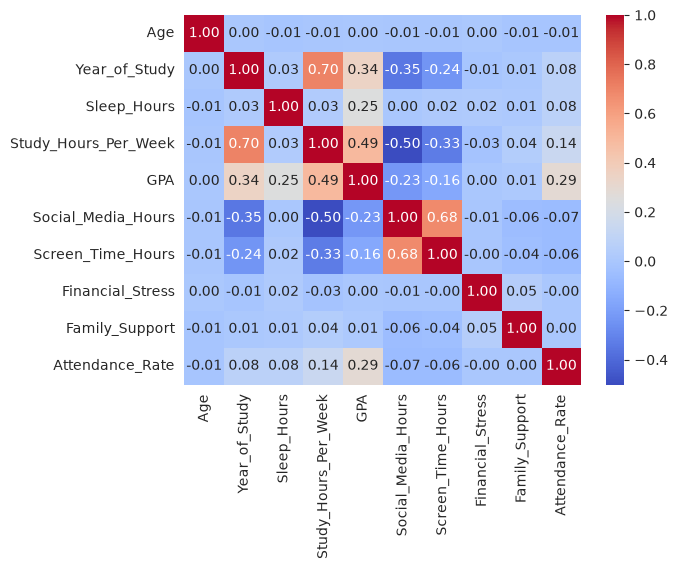

In [27]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

## Distribution of some of the features

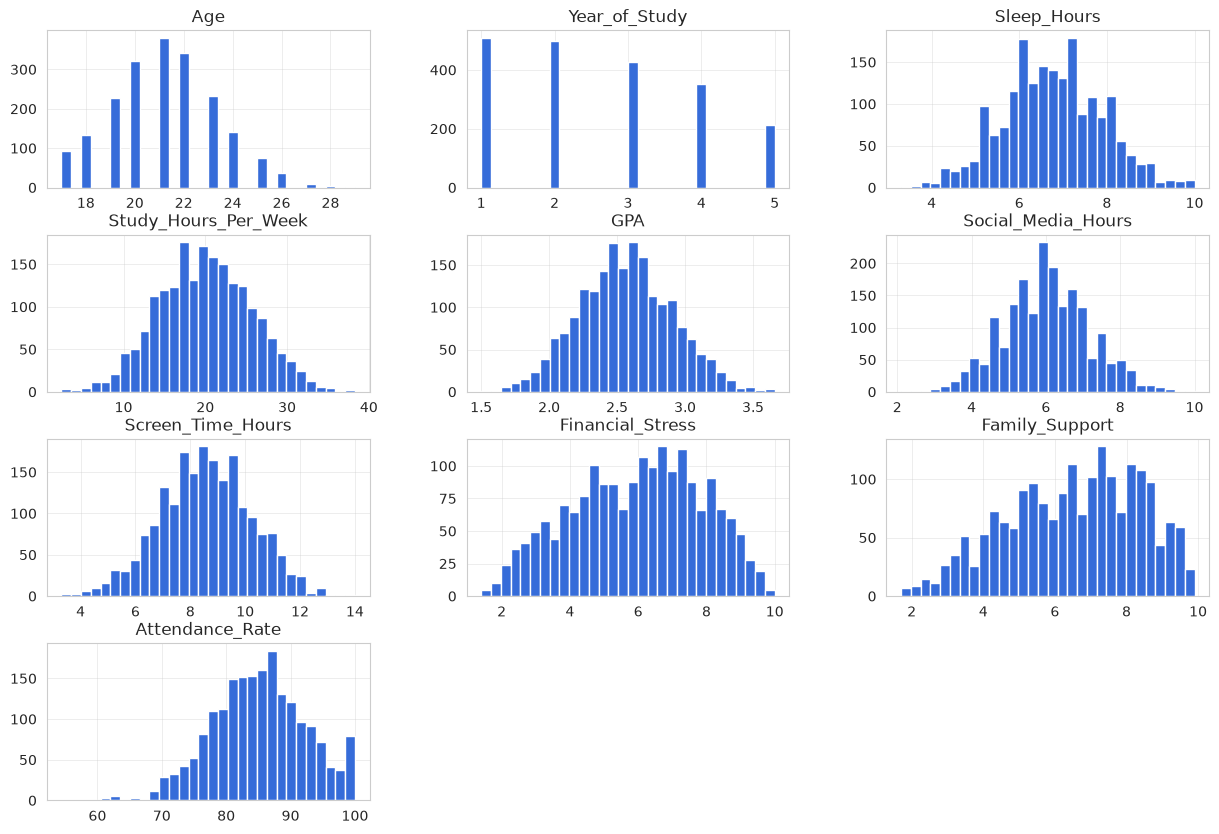

In [28]:
# Let's look at the distribution of some of the numerical features
df.hist(bins=30, figsize=(15, 10))
plt.show()

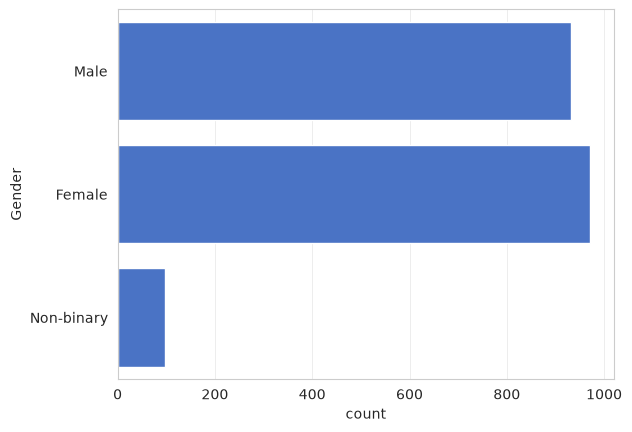

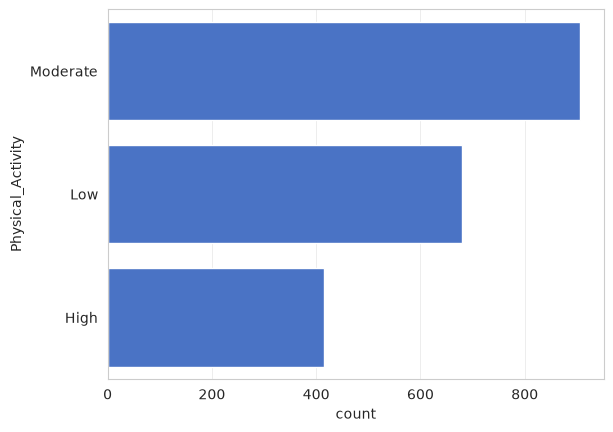

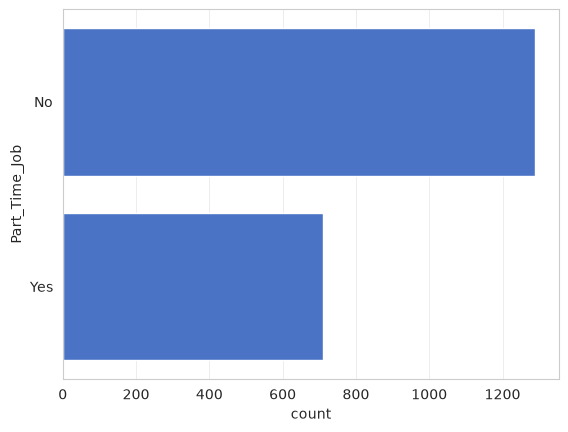

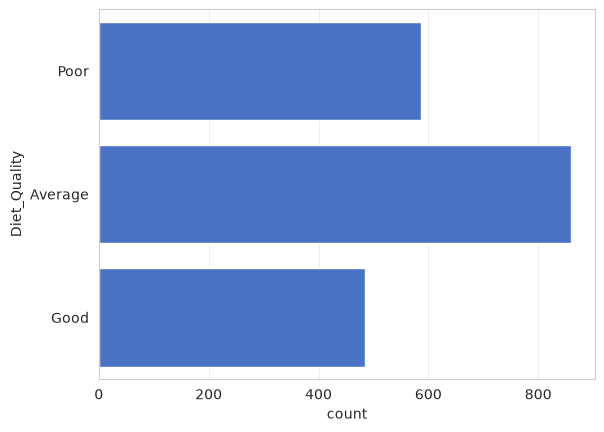

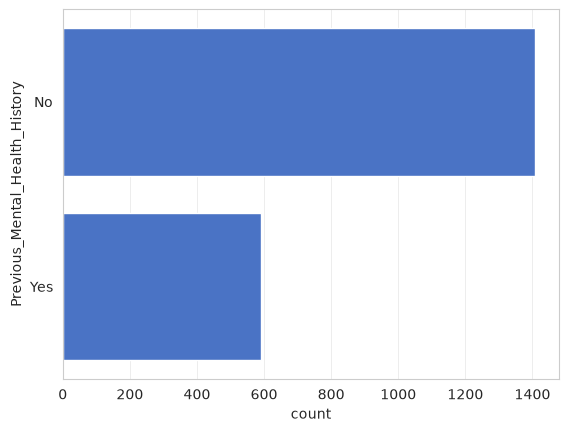

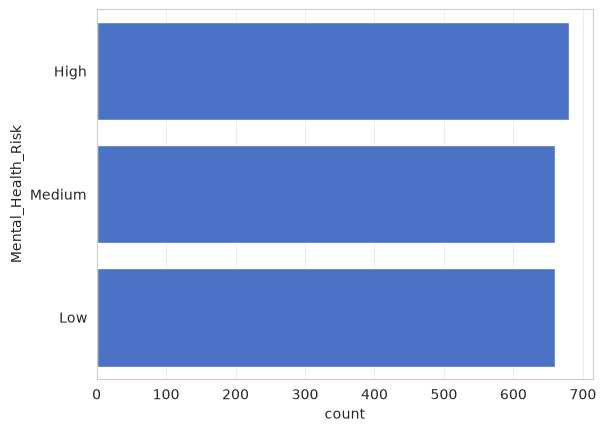

In [33]:
## Let's look at the distribution of some of the categorical features except for the target variable ("Mental_health_Risk") and Student_ID.
categorical_features = df.select_dtypes(include=['object']).columns
categorical_features = categorical_features.drop("Student_ID")

for feature in categorical_features:
    sns.countplot(y=feature, data=df)
    plt.show()&

## Looking for outliers or logically impossible values :

In [34]:
# we start by looking at the screen time column, we will look for values that are logically impossible or outliers like social media time greater than screen time, or screen time greater than 24 hours, or negative values.

df[df['Screen_Time_Hours'] > 24]  # O
df[df['Social_Media_Hours'] > df['Screen_Time_Hours']]  # several rows
df[df['Screen_Time_Hours'] < 0]  # O

df[df["Attendance_Rate"] > 100]
df[df["GPA"] > 4.0] 

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk


In [31]:
df['Social_Media_Hours'] = df['Social_Media_Hours'].clip(upper=df['Screen_Time_Hours'])
invalid = df['Social_Media_Hours'] > df['Screen_Time_Hours']

print(invalid.sum())

0
